# 06 — LGD réalisée par cohorte et contraste crise / normal (étape 5)
Définition « a » (voir `docs/lgd.md`) : LGD = perte réelle / UPB au mois du défaut, sur les défauts liquidés (codes 02/03/09/15) avec perte renseignée. Cohorte = année du défaut.
Ce n'est pas une LGD réglementaire : pas d'actualisation, prêts guéris exclus.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RACINE = Path.cwd().parent
sys.path.insert(0, str(RACINE / "src"))
from validation_toolkit.credit.defaults import dates_defaut, marquer_defaut_souscription, sortie_des_defauts
from validation_toolkit.credit.lgd import echantillon_lgd, lgd_par_pret, lgd_par_cohorte, contraste_regimes

PROC, INTERIM = RACINE / "data" / "processed", RACINE / "data" / "interim"

In [2]:
AN = 2007                    # 2007 ou 2015
SEUIL = 30                   # prêts minimum pour juger une cohorte
NB_TIRAGES = 2000            # bootstrap
REGIMES = [("crise_2008", 2008, 2010), ("stress_2020", 2020, 2020)]   # mêmes frontières que le notebook 04 (à confirmer avec FRED)

## 1. LGD par prêt
Chargée depuis le cache ; recalculée sinon (quelques minutes).

In [3]:
cache = PROC / f"lgd_{AN}.pkl"
if cache.exists():
    lgd = pd.read_pickle(cache)
else:
    perf = INTERIM / f"perf_{AN}.csv"
    dd = marquer_defaut_souscription(perf, dates_defaut(perf))
    ids = echantillon_lgd(sortie_des_defauts(perf, dd), dd)
    lgd = lgd_par_pret(perf, ids, dd)
    lgd.to_pickle(cache)
print(f"{len(lgd):,} prêts ; UPB au défaut manquante : {lgd['upb_defaut'].isna().sum()}")
lgd.drop(columns="id").head()

4,043 prêts ; UPB au défaut manquante : 40


## 2. Forme de la distribution et contrôle du dénominateur

quantiles de la LGD : {0.01: -0.013, 0.1: 0.137, 0.25: 0.313, 0.5: 0.529, 0.75: 0.751, 0.9: 0.972, 0.99: 1.415}
part LGD < 0 (gain) : 1.7% ; part LGD > 1 : 8.4%
écart médian entre les deux dénominateurs : 0.0000 ; maximum : 0.828


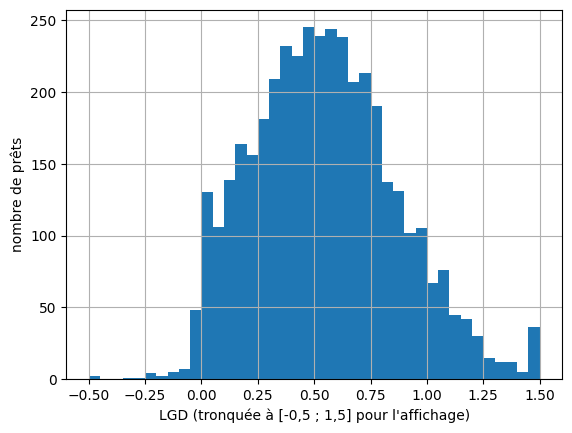

In [4]:
print("quantiles de la LGD :", lgd["lgd"].quantile([.01, .1, .25, .5, .75, .9, .99]).round(3).to_dict())
print(f"part LGD < 0 (gain) : {(lgd['lgd'] < 0).mean():.1%} ; part LGD > 1 : {(lgd['lgd'] > 1).mean():.1%}")
ecart = (lgd["lgd"] - lgd["lgd_upb_sortie"]).abs()
print(f"écart médian entre les deux dénominateurs : {ecart.median():.4f} ; maximum : {ecart.max():.3f}")
lgd["lgd"].clip(-0.5, 1.5).hist(bins=40)
plt.xlabel("LGD (tronquée à [-0,5 ; 1,5] pour l'affichage)"); plt.ylabel("nombre de prêts"); plt.show()

## 3. LGD par année de défaut
`lgd_ponderee` = Σ pertes / Σ UPB ; `concluante` = au moins `SEUIL` prêts ; `delai_median_mois` = mois entre le défaut et la sortie.

In [5]:
coh = lgd_par_cohorte(lgd, seuil=SEUIL)
display(coh.round(3))

,annee_defaut,n,lgd_ponderee,lgd_moyenne,lgd_mediane,delai_median_mois,concluante
0,2007,39,0.522,0.595,0.627,28.0,True
1,2008,491,0.553,0.578,0.558,27.0,True
2,2009,1163,0.523,0.566,0.562,24.0,True
3,2010,901,0.512,0.560,0.545,21.0,True
4,2011,573,0.469,0.529,0.509,16.0,True
5,2012,384,0.412,0.459,0.429,14.0,True
6,2013,208,0.438,0.536,0.510,16.0,True
7,2014,87,0.408,0.539,0.483,15.0,True
8,2015,59,0.501,0.652,0.663,16.0,True
9,2016,38,0.333,0.444,0.374,16.0,True


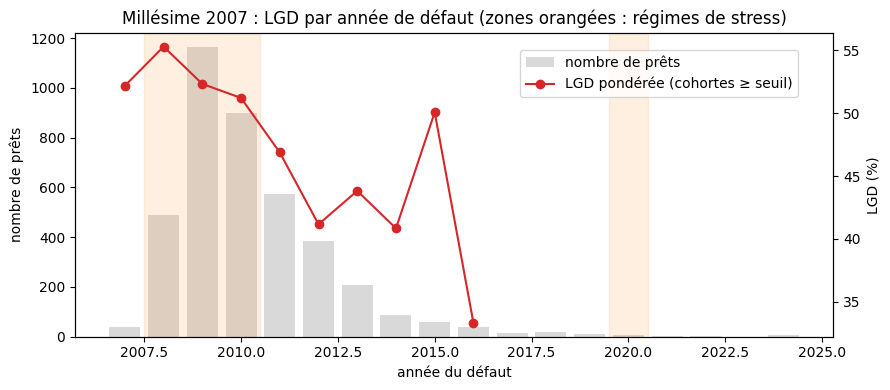

In [6]:
ok = coh[coh["concluante"]]
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(coh["annee_defaut"], coh["n"], color="0.85", label="nombre de prêts")
ax.set_ylabel("nombre de prêts"); ax.set_xlabel("année du défaut")
ax2 = ax.twinx()
ax2.plot(ok["annee_defaut"], 100 * ok["lgd_ponderee"], "o-", color="C3", label="LGD pondérée (cohortes ≥ seuil)")
ax2.set_ylabel("LGD (%)")
for nom, a, b in REGIMES:
    ax.axvspan(a - 0.5, b + 0.5, color="C1", alpha=0.12)
ax.set_title(f"Millésime {AN} : LGD par année de défaut (zones orangées : régimes de stress)")
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.88)); plt.tight_layout(); plt.show()

## 4. Contraste crise / normal
Écart de LGD pondérée (régime − normal) et intervalle à 95 % par bootstrap sur les prêts. L'intervalle ne tient pas compte de la corrélation des pertes entre prêts d'une même année : il est trop étroit pour juger l'effet « crise ».

In [8]:
lignes = []
for nom, _, _ in REGIMES:
    try:
        r = contraste_regimes(lgd, REGIMES, nom, nb_tirages=NB_TIRAGES)
        lignes.append({"regime": nom, "n": r["n_a"], "n_normal": r["n_b"], "lgd_regime": r["lgd_a"],
                       "lgd_normal": r["lgd_b"], "ecart": r["ecart"], "ic95_bas": r["ic95"][0], "ic95_haut": r["ic95"][1],
                       "concluant": r["n_a"] >= SEUIL and r["n_b"] >= SEUIL})
    except ValueError as e:
        lignes.append({"regime": nom, "n": int(lgd["annee_defaut"].between(*[x for x in REGIMES if x[0] == nom][0][1:]).sum()), "remarque": "pas assez de prêts"})
display(pd.DataFrame(lignes).round(3))

,regime,n,n_normal,lgd_regime,lgd_normal,ecart,ic95_bas,ic95_haut,concluant
0,crise_2008,2555,1442,0.525,0.442,0.083,0.064,0.102,True
1,stress_2020,6,1442,-0.037,0.442,-0.479,-0.942,0.147,False


## Limites à retenir
- Définition « a » : ne compte que les défauts liquidés, donc elle surestime la perte par défaut ; pas d'actualisation.
- Les cohortes récentes ne contiennent que des défauts résolus vite : la LGD y est biaisée (voir `delai_median_mois`).
- Dans un millésime, année du défaut et âge du prêt sont liés : « crise » et « prêt plus ancien » ne sont pas séparables.
- 2015 : 134 prêts, une seule année au-dessus du seuil : aucune conclusion.
- Les années 2007 (début de crise) sont classées « normal » par la grille de régimes ; effet faible (39 prêts).